In [19]:
# Imports
import numpy as np
import matplotlib.pyplot as plt

**Initial Experiments on GPG 16 + 22**

In [2]:
# duplicated in infrastructure-profiler/Parser.py

def get_raw_data(filename):
    with open(filename, 'r') as f:
        data = [line.strip() for line in f.readlines() if line.strip()]

    return data


def convert_J_to_kWh(val):
    return val / 3600000


def parse_perf_data(raw):
    # 0 is a datetime, 1 is the summary
    energy_pkg = float(raw[2].split(' ')[0].replace(',', ''))
    energy_ram = float(raw[3].split(' ')[0].replace(',', ''))
    time = float(raw[4].split(' ')[0].replace(',', ''))

    return (convert_J_to_kWh(energy_pkg), convert_J_to_kWh(energy_ram), time)

In [12]:
def get_data_for(filename):
    data = {'energy_pkg': [], 'energy_ram': [], 'time': []}

    for iteration in range(1, 4):
        raw = get_raw_data(f'{filename}-{iteration}.txt')
        vals = parse_perf_data(raw)

        data['energy_pkg'].append(vals[0])
        data['energy_ram'].append(vals[1])
        data['time'].append(vals[2])

    return data

In [14]:
def get_mean_and_std(arr):
    return np.mean(arr), np.std(arr)

def get_avg_perf_data(data):
    energy_pkg_mean, energy_pkg_std = get_mean_and_std(data['energy_pkg'])
    energy_ram_mean, energy_ram_std = get_mean_and_std(data['energy_ram'])
    time_mean, time_std = get_mean_and_std(data['time'])

    return {'energy_pkg': (energy_pkg_mean, energy_pkg_std),
            'energy_ram': (energy_ram_mean, energy_ram_std), 
            'time': (time_mean, time_std)}

Tasks
1. Predict Runtime (runtime scale-up factor)
2. Predict Energy Consumption (node energy model with runtime)
3. Predict for Another Node (translation for other node? node translation factor)

In [35]:
# perf data (energy + time) -- plot mean + s.d.

gpg16_data = {
    'fastqc': {
        30: get_avg_perf_data(get_data_for('augur-gpg16/split30/perf-fastqc')),
        25: get_avg_perf_data(get_data_for('augur-gpg16/split25/perf-fastqc')),
        20: get_avg_perf_data(get_data_for('augur-gpg16/split20/perf-fastqc')),
        16: get_avg_perf_data(get_data_for('augur-gpg16/split16/perf-fastqc')),
        10: get_avg_perf_data(get_data_for('augur-gpg16/split10/perf-fastqc')),
        8: get_avg_perf_data(get_data_for('augur-gpg16/split8/perf-fastqc')),
        4: get_avg_perf_data(get_data_for('augur-gpg16/split4/perf-fastqc'))
    }, 
    'trimgalore': {
        30: get_avg_perf_data(get_data_for('augur-gpg16/split30/perf-trimgalore')),
        25: get_avg_perf_data(get_data_for('augur-gpg16/split25/perf-trimgalore')),
        20: get_avg_perf_data(get_data_for('augur-gpg16/split20/perf-trimgalore')),
        16: get_avg_perf_data(get_data_for('augur-gpg16/split16/perf-trimgalore')),
        10: get_avg_perf_data(get_data_for('augur-gpg16/split10/perf-trimgalore')),
        8: get_avg_perf_data(get_data_for('augur-gpg16/split8/perf-trimgalore')),
        4: get_avg_perf_data(get_data_for('augur-gpg16/split4/perf-trimgalore'))
    }
}

splits = [30,25,20,16,10,8,4]
split_per = [0.03333333333, 0.04, 0.05, 0.0625, 0.1, 0.125, 0.25]

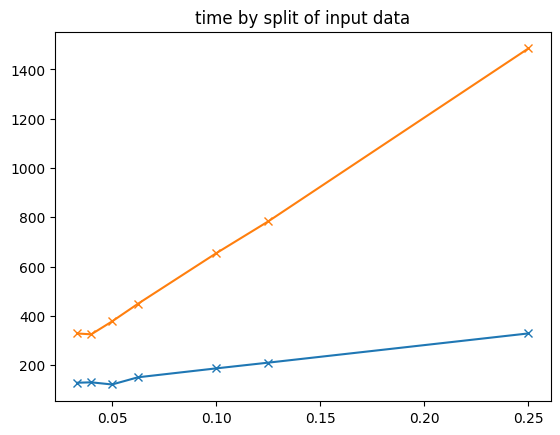

In [34]:
fastqc_time = [gpg16_data['fastqc'][k]['time'][0] for k in splits]
trimgalore_time = [gpg16_data['trimgalore'][k]['time'][0] for k in splits]

plt.plot(split_per, fastqc_time, marker='x')
plt.plot(split_per, trimgalore_time, marker='x')
plt.title('time by split of input data')
plt.show()

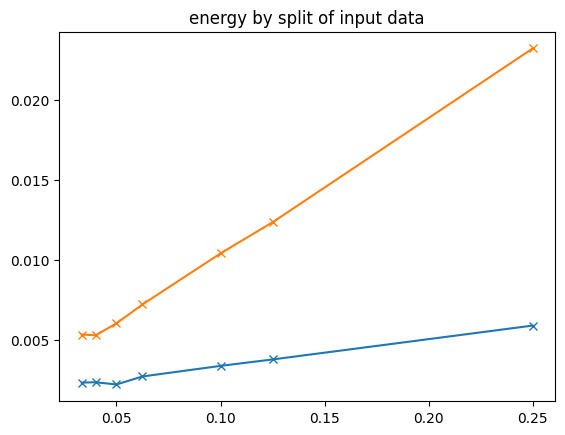

In [37]:
fastqc_energy = [gpg16_data['fastqc'][k]['energy_pkg'][0] + gpg16_data['fastqc'][k]['energy_ram'][0] for k in splits]
trimgalore_energy = [gpg16_data['trimgalore'][k]['energy_pkg'][0] + gpg16_data['fastqc'][k]['energy_ram'][0] for k in splits]

plt.plot(split_per, fastqc_energy, marker='x')
plt.plot(split_per, trimgalore_energy, marker='x')
plt.title('energy by split of input data')
plt.show()

In [56]:
# plotting standard deviation ?! 

# x = np.array([1, 2, 3, 4, 5])
# y = np.power(x, 2) # Effectively y = x**2
# e = np.array([1.5, 2.6, 3.7, 4.6, 5.5])

# plt.errorbar(x, y, e, linestyle='None', marker='x')

In [73]:
# Runtime Scaling factor on GPG 16 ?

# fastqc
factor = gpg16_data['fastqc'][10]['time'][0] / gpg16_data['fastqc'][16]['time'][0] 
# 0.0625 -> 0.10 (data expansion rate) 1.6 
loss_factor = (factor / 1.6)
pred_fastqc = gpg16_data['fastqc'][10]['time'][0] * 2.5 * loss_factor
print('predicted fastqc runtime: ', pred_fastqc)
actual_fastqc = gpg16_data['fastqc'][4]['time'][0]
print('actual fastqc runtime:', actual_fastqc)
print('error%: ', (abs(pred_fastqc - actual_fastqc) / actual_fastqc) * 100)  # pred - actual / actual x100%
print('loss factor: ', loss_factor)

# trimgalore
factor = gpg16_data['trimgalore'][10]['time'][0] / gpg16_data['trimgalore'][16]['time'][0] 
# 0.0625 -> 0.10 (data expansion rate) 1.6 
loss_factor = (factor / 1.6)
pred_trimgalore = gpg16_data['trimgalore'][10]['time'][0] * 2.5 * loss_factor
print('predicted trimgalore runtime: ', pred_trimgalore)
actual_trimgalore = gpg16_data['trimgalore'][4]['time'][0]
print('actual trimgalore runtime:', actual_trimgalore)
print('error%: ', (abs(pred_trimgalore - actual_trimgalore) / actual_trimgalore) * 100)
print('loss factor: ', loss_factor)



predicted fastqc runtime:  362.5066653228707
actual fastqc runtime: 329.15967551566666
error%:  10.130946251226582
loss factor:  0.7736561946468326
predicted trimgalore runtime:  1486.7094137538854
actual trimgalore runtime: 1484.6626358613332
error%:  0.13786148065649628
loss factor:  0.9090692302374268


In [ ]:
# runtime on gpg 22
gpg22_data = {
    'fastqc': {
        8: get_avg_perf_data(get_data_for('gpg22/fastqc/split8/perf-fastqc')),
        4: get_avg_perf_data(get_data_for('gpg22/fastqc/split4/perf-fastqc'))
    }, 
    'trimgalore': {
        8: get_avg_perf_data(get_data_for('gpg22/trimgalore/split8/perf-trimgalore')),
        4: get_avg_perf_data(get_data_for('gpg22/trimgalore/split4/perf-trimgalore'))
    }
}

print('gpg16')
print(gpg16_data['fastqc'][8]['time'][0])
print(gpg16_data['trimgalore'][8]['time'][0])

print('gpg22')
print(gpg22_data['fastqc'][8]['time'][0])
print(gpg22_data['trimgalore'][8]['time'][0])

fastqc_device_factor = gpg22_data['fastqc'][8]['time'][0] / gpg16_data['fastqc'][8]['time'][0]
trimgalore_device_factor = gpg22_data['trimgalore'][8]['time'][0] / gpg16_data['trimgalore'][8]['time'][0]

print(fastqc_device_factor)
print(trimgalore_device_factor)

print('gpg16 predicted runtime')
print(pred_fastqc)
print(pred_trimgalore)

print('gpg22 predicted runtime from gpg16')
gpg22_pred_fastqc = pred_fastqc * fastqc_device_factor
gpg22_pred_trimgalore = pred_trimgalore * trimgalore_device_factor
gpg22_fastqc_actual = gpg22_data['fastqc'][4]['time'][0]
gpg22_trimgalore_actual = gpg22_data['trimgalore'][4]['time'][0]
print('fastqc pred: ', gpg22_pred_fastqc, '\nactual: ', gpg22_fastqc_actual)
gpg22_err_fast = (abs(gpg22_pred_fastqc - gpg22_fastqc_actual) / gpg22_fastqc_actual) * 100
print(gpg22_err_fast, '%')
print('trimgalore pred: ', gpg22_pred_trimgalore, '\nactual: ', gpg22_trimgalore_actual)
gpg22_err_trim = (abs(gpg22_pred_trimgalore - gpg22_trimgalore_actual) / gpg22_trimgalore_actual) * 100
print(gpg22_err_trim, '%')

# error % here is like 4% more than it was on the other node, less than expected -- defo room for improvement though 

# energy predicted using predicted runtime?
fastqc_pred_time_h = gpg22_pred_fastqc / 3600
trimgalore_pred_time_h = gpg22_pred_trimgalore / 3600
fastqc_cpu_usage = 100.1 / 64 
trimgalore_cpu_usage = 111.1 / 64 
fastqc_pred_energy = fastqc_pred_time_h * (fastqc_cpu_usage * 1.6530484848484859 + 193.20121212121217) * 0.001
trimgalore_pred_energy = trimgalore_pred_time_h * (trimgalore_cpu_usage * 1.6530484848484859 + 193.20121212121217) * 0.001
fastqc_actual_energy = gpg22_data['fastqc'][4]['energy_pkg'][0] + gpg22_data['fastqc'][4]['energy_ram'][0]
trimgalore_actual_energy = gpg22_data['trimgalore'][4]['energy_pkg'][0] + gpg22_data['trimgalore'][4]['energy_ram'][0]

print(f'fastqc predicted: {fastqc_pred_energy:.3f}kWh actual: {fastqc_actual_energy:.3f}')
print(f'trimgalore predicted: {trimgalore_pred_energy:.3f}kWh actual: {trimgalore_actual_energy:.3f}')

# energy predicted using node energy consumption and translation factor (?)




gpg16
210.6666601533333
783.2926481263333
gpg22
108.77125308433334
464.80172885366665
0.5163192552877821
0.5933947292439047
gpg16 predicted runtime
362.5066653228707
1486.7094137538854
gpg22 predicted runtime from gpg16
fastqc pred:  187.16917147636184 
actual:  163.85409197599998
14.22917134335398 %
trimgalore pred:  882.2055300388511 
actual:  842.0895100496667
4.763866490489625 %
0.24505709167745862
fastqc predicted: 0.010kWh actual: 0.009
trimgalore predicted: 0.048kWh actual: 0.040
